# Linear Regression

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score
from sklearn.model_selection import train_test_split

- Bias (intercept): The predicted value of \(y\) when all input features are zero.
- Weight (coefficient): How much the predicted value of \(y\) changes when a feature increases by one unit.

In [3]:
from wrangle import clean_files
df=clean_files("../data/buenos-aires-real-estate-*.csv")
df.info()

<class 'pandas.DataFrame'>
Index: 6247 entries, 7 to 43026
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        6247 non-null   float64
 1   surface_covered_in_m2  6247 non-null   float64
 2   lat                    6247 non-null   float64
 3   lon                    6247 non-null   float64
 4   neighborhood           6247 non-null   str    
dtypes: float64(4), str(1)
memory usage: 292.8 KB


## split target and feature

In [4]:
# feature matrix
X=df[["surface_covered_in_m2"]]

# target
y=df["price_aprox_usd"]

## Split train and test

### Why Split Data?

A model trained and evaluated on the same data would appear to perform perfectly — it has already seen every example. But that score is meaningless for real-world use, because in practice we will always predict prices for new listings the model was never trained on.

The train-test split enforces discipline: the model learns from training data, and we measure its real performance on test data it has never seen. Only test-set metrics are honest estimates of real-world performance.

  - Training set (80%): Used for learning — the model sees these examples and adjusts its coefficients
  - test set (20%): Held out entirely until evaluation — the model never uses these during training
  
We use test_size=0.2 (20% test) and random_state=42 for reproducibility

In [5]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

Training set size: 4997
Test set size: 1250


### Baseline

Before building any model, we need a baseline — the simplest possible prediction strategy — as a performance benchmark.

A baseline answers the question: "How well could we do without any modeling at all?

**The mean baseline**: If someone asked you "how much does a Buenos Aires apartment cost?" and you had to give one number for every apartment regardless of size, your best answer would be the mean price across all training examples. This is the most naïve possible prediction — it ignores all features and simply returns the average for every single query.

**Why the mean, specifically?** The mean minimizes the sum of squared deviations. In other words, if you must predict the same value for everyone, the mean produces the smallest total squared error.

The baseline as a minimum bar: Any model that performs worse than the mean baseline is not just unhelpful — it is actively destructive.


In [6]:
y_mean=y_train.mean()
print("Mean house price:", y_mean)

Mean house price: 134308.64565939564


In [7]:
y_pred_baseline =[y_mean] * len(y_test)
y_pred_baseline

[np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float64(134308.64565939564),
 np.float6

In [8]:
### calculate mean absolute error
mae_baseline=mean_absolute_error(y_test,y_pred_baseline)
print("Baseline MAE:", mae_baseline)

Baseline MAE: 45691.39151253952


Linear regression finds the line of best fit by trying to minimize the sum of squared errors between actual values and predicted values

Scikit-learn uses Ordinary Least Squares (OLS) to find the bias and weight that minimize the sum of squared errors between actual and predicted prices.

OLS is a mathematical method for finding the best-fitting line by minimizing the sum of squared differences between actual values and predicted values.



Three-step pattern 
- instantiate 
   
   Step 1: Instantiate — create the model object with hyperparameters

    model = LinearRegression()
- fit 
  
   Step 2: Fit — train on labeled data (model learns β₀ and β₁)

    model.fit(X_train, y_train)
- predict 
  
    Step 3: Predict — generate predictions for any feature matrix

    y_pred = model.predict(X_new)


     Why separate instantiation from fitting? Separating object creation from training lets you configure the model's hyperparameters (like the regularization strength for Ridge or Lasso) before exposing it to data. It also makes the workflow explicit: model definition is separate from model training, which is separate from model evaluation.

     Hyperparameters are settings you choose before training a machine learning model. They control how the model is configured or how it learns.

In [9]:
model_lr=LinearRegression()
model_lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2249.77]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['surface_covered_in_m2']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.236e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


### Evaluating the model 
1. MAE (Mean Absolute Error): How far off your predictions are on average.
2. RMSE (Root Mean Squared Error): How large your prediction errors are, with extra penalty for large mistakes.
3. Coefficient of determination (\(R^2\)): How well your model explains the variation in apartment prices compared with simply predicting the mean





### 3. Example using house prices

Suppose the actual and predicted prices are:

| Actual Price | Predicted Price | Absolute Error | Squared Error |
| ------------ | --------------- | -------------- | ------------- |
| $100,000     | $110,000        | $10,000        | 100,000,000   |
| $150,000     | $130,000        | $20,000        | 400,000,000   |
| $200,000     | $190,000        | $10,000        | 100,000,000   |
| Total        |                 | $40,000        | 600,000,000   |

| Metric | Calculation                     | Result     |
| ------ | ------------------------------- | ---------- |
| MAE    | $40,000 ÷ 3                     | $13,333.33 |
| RMSE   | \\(\sqrt{600,000,000 \div 3}\\) | $14,142.14 |

Key takeaway: MAE tells you the average size of your prediction errors. 
RMSE highlights larger errors more strongly. R² tells you how well your model explains variation compared with a mean-based prediction.

### coefficient of determination (\(R^2\))
The coefficient of determination (\\(R^2\\)) measures how well a regression model explains the variation in the target variable compared with predicting the mean.

In your Buenos Aires housing project, it tells you how well your model explains the differences in apartment prices.

## 1. Understanding it with an example

Imagine you want to predict apartment prices.

Some apartments cost $80,000, others $150,000, and others $250,000. These differences are called variation in prices.

Your model uses features such as surface area and location to predict those prices.

- If the model explains most of the differences in prices, \\(R^2\\) will be closer to 1.
- If it performs about as well as predicting the mean price for every apartment, \\(R^2\\) will be around 0.
- If it performs worse than that mean-based prediction, \\(R^2\\) can be negative.

## 2. Interpreting \\(R^2\\)

| R² value | Meaning                                                                       |
| -------- | ----------------------------------------------------------------------------- |
| 1.0      | Perfect predictions on the evaluated data                                     |
| 0.8      | The model explains 80% of the variation relative to the mean-based reference  |
| 0.5      | The model explains 50% of the variation relative to the mean-based reference  |
| 0.0      | The model performs as well as the mean-based reference in squared-error terms |
| -0.2     | The model performs worse than the mean-based reference                        |

These values describe performance on the particular dataset being evaluated. A high training \\(R^2\\) does not guarantee good performance on test data.

## 3. How is it calculated?

The formula is:

\\[ R^2=1-\frac{\text{Sum of squared prediction errors}}{\text{Total sum of squares}} \\]

Where:

- Sum of squared prediction errors: How far the model's predictions are from the actual prices.
- Total sum of squares: How far the actual prices are from their mean.

The model's errors are compared with the errors from using the mean as the prediction.



In [10]:
y_pred_train=model_lr.predict(X_train)
mae_train=mean_absolute_error(y_train,y_pred_train)
rmse_train=root_mean_squared_error(y_train,y_pred_train)
r2_train=r2_score(y_train,y_pred_train)

print(f"Training MAE: ${mae_train:,.2f}")
print(f"Training RMSE: ${rmse_train:,.2f}")
print(f"Training R²: {r2_train:.4f}")


Training MAE: $30,967.16
Training RMSE: $42,824.66
Training R²: 0.4741


In [11]:
y_pred_test=model_lr.predict(X_test)
mae_test=mean_absolute_error(y_test,y_pred_test)
rmse_test=root_mean_squared_error(y_test,y_pred_test)
r2_test=r2_score(y_test,y_pred_test)

print(f"Test MAE: ${mae_test:,.2f}")
print(f"Test RMSE: ${rmse_test:,.2f}")
print(f"Test R²: {r2_test:.4f}")

Test MAE: $30,959.32
Test RMSE: $42,878.74
Test R²: 0.4921


### Diagnosing the Model: Training vs. Test Gap

### Overfitting (train ≪ test error)

RMSE_train is substantially lower than RMSE_test. The model has memorized the training data — it performs well on examples it has seen but generalizes poorly to new ones.

#### Cause: 
- Model is too complex relative to the data
- too many features; 
- outliers not removed; 
- data leakage. 
#### Fix: 
- Regularization , 
- feature selection, 
- more training data, or stricter data cleaning.


### Underfitting (both train and test errors are high)

Both RMSE values are large — the model fails on training data and test data. The model is too simple to capture the underlying relationship.

#### Cause: 
- Not enough features, 
- wrong model family, 
-  a real relationship that cannot be captured linearly. 
#### Fix: 
- Add more features, 
- try a more complex model, or 
- engineer non-linear features.

### Good Fit (train ≈ test, both reasonably low)

Training and test errors are close to each other and acceptably low. The model has learned a generalizable pattern, not memorized specific examples.

- For communicating with stakeholders: MAE is most intuitive — "we are off by $X on average." 
- For optimization and model selection: RMSE is often preferred because it penalizes large errors more harshly, matching the real cost of badly wrong predictions. 
- R² gives relative context — how much better are we than always predicting the mean?

In [12]:
metrics_comparison=pd.DataFrame({
    'Metrics':["MAE","RMSE","R2"],
    "TRAINING":[mae_train,rmse_train,r2_train],
    "test":[mae_test,rmse_test,r2_test]
})
print(metrics_comparison)

  Metrics      TRAINING          test
0     MAE  30967.162647  30959.319396
1    RMSE  42824.658233  42878.737867
2      R2      0.474149      0.492122


In [13]:
print(f"\nRMSE difference (Test - Train): ${rmse_test - rmse_train:,.2f}")


RMSE difference (Test - Train): $54.08


After fitting, the model has learned two parameters that define the line of best fit: the intercept () and the coefficient ().

In [14]:
intercept=model_lr.intercept_
coefficient=model_lr.coef_[0]

print(f"Intercept: ${intercept:,.2f}")
print(f"Coefficient: ${coefficient:,.2f} per square meter")

Intercept: $12,364.06
Coefficient: $2,249.77 per square meter


### Predicted vs. Actual Plot

The predicted-vs-actual scatter plot is one of the most informative model diagnostics available. It compares the model's predictions (x-axis) to the true prices (y-axis).

How to read it:

- Perfect predictions: Every point falls on the 45° diagonal line (where predicted = actual)
- Points above the diagonal: The model underestimated — actual price is higher than predicted
- Points below the diagonal: The model overestimated — actual price is lower than predicted
- Tight cluster around the diagonal: Low prediction error overall
- Wide scatter off the diagonal: Large errors; the model is missing important signals

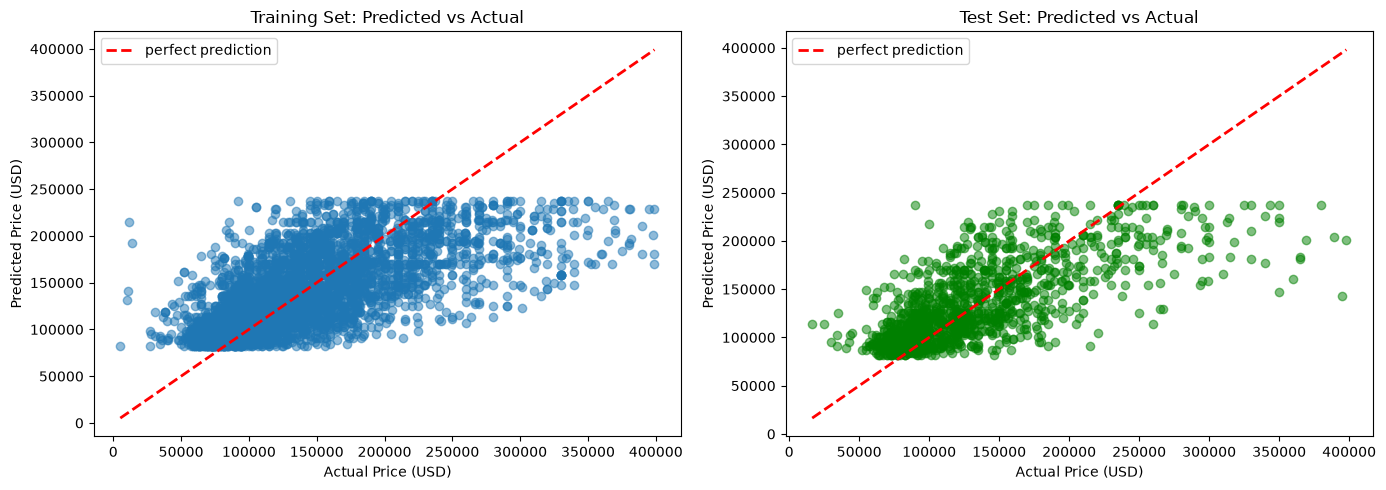

In [16]:
fig,axes=plt.subplots(1,2,figsize=(14,5))

# Training set
axes[0].scatter(y_train,y_pred_train,alpha=0.5)
axes[0].plot([y_train.min(),y_train.max()],[y_train.min(),y_train.max()],'r--',lw=2,label="perfect prediction")
axes[0].set_xlabel('Actual Price (USD)')
axes[0].set_ylabel('Predicted Price (USD)')
axes[0].set_title('Training Set: Predicted vs Actual')
axes[0].legend()

# Test set
axes[1].scatter(y_test,y_pred_test,alpha=0.5,color="green")
axes[1].plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],"r--",lw=2,label="perfect prediction")
axes[1].set_xlabel('Actual Price (USD)')
axes[1].set_ylabel('Predicted Price (USD)')
axes[1].set_title('Test Set: Predicted vs Actual')
axes[1].legend()

plt.tight_layout()